In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!git clone https://github.com/EngineerAmor/Learning-ImageNet-Representations-with-Variational-Autoencoders-and-GANs.git repo
%cd repo

Cloning into 'repo'...
remote: Enumerating objects: 12756, done.
remote: Counting objects: 100% (12756/12756), done.
remote: Compressing objects: 100% (4185/4185), done.
remote: Total 12756 (delta 8571), reused 12710 (delta 8562), pack-reused 0 (from 0)
Receiving objects: 100% (12756/12756), 30.44 MiB | 35.42 MiB/s, done.
Resolving deltas: 100% (8571/8571), done.
/content/repo


In [ ]:
!ls
!ls T12_Splits
!cat DATA_FORMAT.md
!find . -name "*.npz" -o -name "*.npy" -o -name "*.pt"

configs		notebooks  results  src		tests
DATA_FORMAT.md	README.md  scripts  T12_Splits
metadata.json	  test		   train	     val
README.txt	  test_index.csv   train_index.csv   val_index.csv
split_counts.csv  test_index.json  train_index.json  val_index.json
# T12 Dataset Array & Split Index Format (Member A Deliverable)

## 1. Single Array File (`results/data/dataset.npz`)

Generated from `T12_Splits/` via:

```bash
python3 scripts/build_dataset.py
```

Archive format: compressed NumPy `.npz` containing the exact four keys expected by `load()` in `train_vae.py`:

| Key | Dtype | Shape | Layout / Semantics | Value Range |
| :--- | :--- | :--- | :--- | :--- |
| `x` | `uint8` | `(12653, 64, 64, 3)` | NHWC, RGB channel order | `0`–`255` |
| `y` | `int64` | `(12653,)` | Contiguous class labels (`train_label`) | `0`–`9` |
| `train_idx` | `int64` | `(11388,)` | 0-based indices into `x` and `y` for TRAIN (`0..11387`) | `0`–`11387` |
| `val_idx` | `int64` | `(1265,)` | 0-based indices into `x` an

In [ ]:
import sys
sys.path.insert(0, "/content/repo/src")
from vae.model import VAE
print("OK")

OK


In [6]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [10]:
!ls -la /content/drive/MyDrive/CI_Checkpoints_M1

ls: /content/drive/MyDrive/CI_Checkpoints_M1
lrw------- 1 root root 0 Nov 26 19:19 /content/drive/MyDrive/CI_Checkpoints_M1 -> /content/drive/.shortcut-targets-by-id/1jIowvV_l4pK7qoiIGQnYb5iiPVcF7jYq/CI_Checkpoints_M1


In [12]:
!find /content/drive/MyDrive/CI_Checkpoints_M1 -name "*z128*"

In [13]:
ckpt = "/content/drive/MyDrive/CI_Checkpoints_M1/vae_z128_final.pt"
!sha256sum "{ckpt}"

3c1c652890a9df4735f563e79ff4ac0eb61c99df043d5fd25be6a0e0379e63d3  /content/drive/MyDrive/CI_Checkpoints_M1/vae_z128_final.pt


In [14]:
!ls /content/repo/T12_Splits

metadata.json	  test		   train	     val
README.txt	  test_index.csv   train_index.csv   val_index.csv
split_counts.csv  test_index.json  train_index.json  val_index.json


In [15]:
!cat /content/repo/DATA_FORMAT.md

# T12 Dataset Array & Split Index Format (Member A Deliverable)

## 1. Single Array File (`results/data/dataset.npz`)

Generated from `T12_Splits/` via:

```bash
python3 scripts/build_dataset.py
```

Archive format: compressed NumPy `.npz` containing the exact four keys expected by `load()` in `train_vae.py`:

| Key | Dtype | Shape | Layout / Semantics | Value Range |
| :--- | :--- | :--- | :--- | :--- |
| `x` | `uint8` | `(12653, 64, 64, 3)` | NHWC, RGB channel order | `0`–`255` |
| `y` | `int64` | `(12653,)` | Contiguous class labels (`train_label`) | `0`–`9` |
| `train_idx` | `int64` | `(11388,)` | 0-based indices into `x` and `y` for TRAIN (`0..11387`) | `0`–`11387` |
| `val_idx` | `int64` | `(1265,)` | 0-based indices into `x` and `y` for VAL (`11388..12652`) | `11388`–`12652` |

> **TEST is never touched:** `T12_Splits/test/` is empty and excluded. `x`, `y`, `train_idx`, and `val_idx` contain only TRAIN (11,388 images) and VAL (1,265 images).

## 2. Confirmation for `load()` in `

In [16]:
!find /content/repo -name "*.npz" -o -name "*.npy" -o -name "*.json" | head -30
!ls -lh /content/repo

/content/repo/results/data/train_idx.json
/content/repo/results/data/train_idx.npy
/content/repo/results/data/dataset_format.json
/content/repo/results/data/val_idx.json
/content/repo/results/data/val_idx.npy
/content/repo/results/runs/vae_warmup_off.json
/content/repo/results/runs/vae_beta4.json
/content/repo/results/runs/vae_z128.json
/content/repo/results/runs/vae_z32.json
/content/repo/results/runs/vae_default.json
/content/repo/results/runs/vae_beta0.25.json
/content/repo/results/selected_vae.json
/content/repo/T12_Splits/val_index.json
/content/repo/T12_Splits/test_index.json
/content/repo/T12_Splits/train_index.json
/content/repo/T12_Splits/metadata.json
/content/repo/configs/vae_study.json
total 36K
drwxr-xr-x 2 root root 4.0K Nov 26 19:05 configs
-rw-r--r-- 1 root root 3.5K Nov 26 19:05 DATA_FORMAT.md
drwxr-xr-x 2 root root 4.0K Nov 26 19:05 notebooks
-rw-r--r-- 1 root root 2.5K Nov 26 19:05 README.md
drwxr-xr-x 5 root root 4.0K Nov 26 19:05 results
drwxr-xr-x 3 root root 4.0K

In [17]:
import torch
from vae.model import VAE

ckpt = "/content/drive/MyDrive/CI_Checkpoints_M1/vae_z128_final.pt"
vae = VAE(latent_dim=128)
vae.load_state_dict(torch.load(ckpt, map_location="cpu"))
vae.eval()
print("VAE loaded OK, params:", sum(p.numel() for p in vae.parameters()))

VAE loaded OK, params: 2957955


In [18]:
%cd /content/repo
!mkdir -p results/data
!python3 scripts/build_dataset.py

/content/repo
Built /content/repo/results/data/dataset.npz: x=(12653, 64, 64, 3) (uint8), y=(12653,) (int64), train_idx=(11388,), val_idx=(1265,)


In [19]:
!ls -lh /content/repo/results/data

total 131M
-rw-r--r-- 1 root root 1.6M Nov 26 19:39 array_index.csv
-rw-r--r-- 1 root root 3.0K Nov 26 19:39 dataset_format.json
-rw-r--r-- 1 root root 129M Nov 26 19:39 dataset.npz
-rw-r--r-- 1 root root  67K Nov 26 19:39 train_idx.json
-rw-r--r-- 1 root root  90K Nov 26 19:39 train_idx.npy
-rw-r--r-- 1 root root 8.7K Nov 26 19:39 val_idx.json
-rw-r--r-- 1 root root  11K Nov 26 19:39 val_idx.npy


In [20]:
import numpy as np, torch, os
from vae.model import VAE

ckpt = "/content/drive/MyDrive/CI_Checkpoints_M1/vae_z128_final.pt"
vae = VAE(latent_dim=128)
vae.load_state_dict(torch.load(ckpt, map_location="cpu"))
vae.eval()

d = np.load("/content/repo/results/data/dataset.npz")
val_idx = d["val_idx"]
X_val = d["x"][val_idx]
y_val = d["y"][val_idx]
print(X_val.shape, X_val.dtype, "| classes:", np.bincount(y_val, minlength=10))

x = torch.from_numpy(X_val).permute(0, 3, 1, 2).float() / 255.0

mus = []
with torch.no_grad():
    for i in range(0, len(x), 256):
        mu, logvar = vae.encoder(x[i:i+256])
        mus.append(mu)
mu_val = torch.cat(mus).numpy()
print("mu_val:", mu_val.shape)

np.save("/content/repo/results/mu_val.npy", mu_val)
np.save("/content/repo/results/y_val.npy", y_val)

(1265, 64, 64, 3) uint8 | classes: [130 114 130 122 130 119 130 130 130 130]
mu_val: (1265, 128)


In [21]:
var = mu_val.var(axis=0)
print("Active units (var>0.01):", (var > 0.01).sum(), "/ 128")
print("min var:", var.min(), "| max var:", var.max())

Active units (var>0.01): 128 / 128
min var: 0.0128979515 | max var: 1.6474185


In [23]:
text = """

---

## Study 2: Milestone 1, Latent Space Analysis (Member C)

- Author: Nourhan Alaa (Member C, Latent Analysis)
- Date written (before running t-SNE/UMAP, traversals, interpolations): 2026-11-26

### Predictions and Reasoning

1. Flat-coated and curly-coated retriever will overlap the most in the latent space, because both are black dogs with a similar head shape.
2. Dhole will sit close to the retrievers (brown dog-like body, similar poses and backgrounds).
3. Terrapin and red-breasted merganser may partly overlap (water, mud and green backgrounds).
4. Chain saw, water bottle and butternut squash will be more separated from the animal classes.
5. Overall, classes will overlap a lot, because the VAE is trained only to reconstruct, so it groups images by colour, lighting and background, not by class.
6. The most active latent dimensions will mostly encode global properties like brightness and background colour, not object identity.
"""

with open("/content/repo/results/predictions.md", "a", encoding="utf-8") as f:
    f.write(text)

print("Done")

Done


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


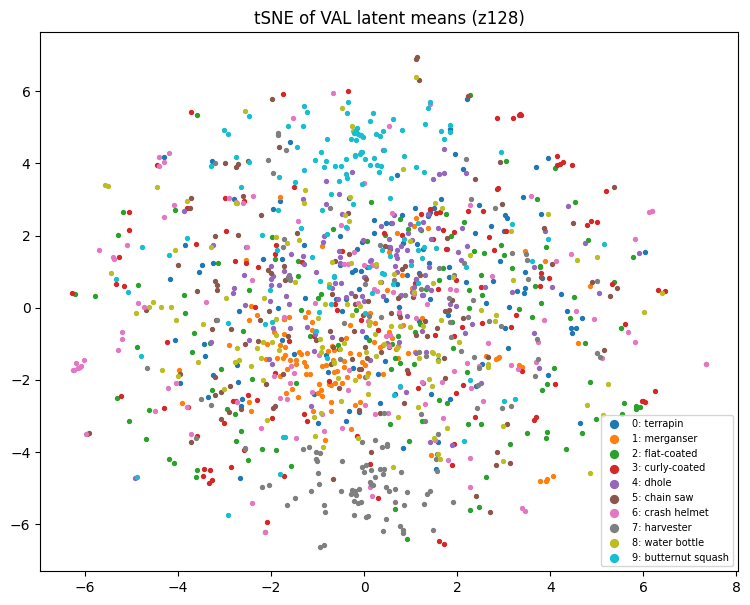

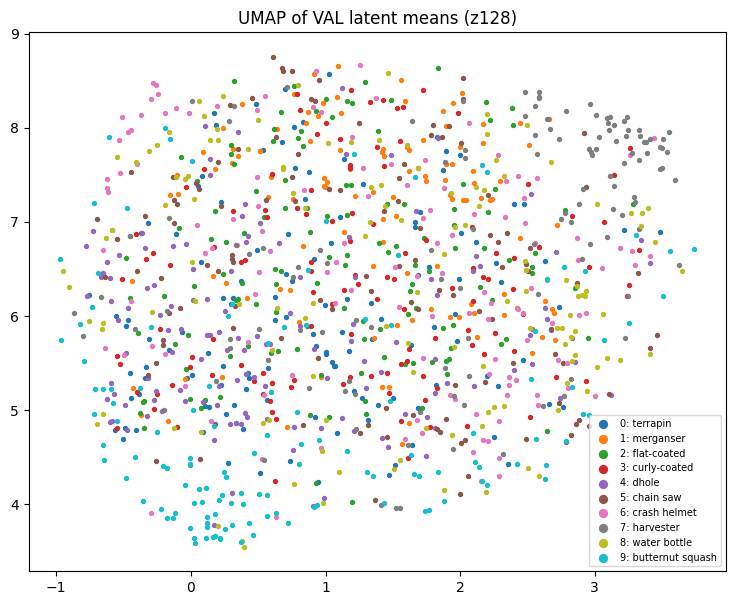

In [24]:
import numpy as np, matplotlib.pyplot as plt, os
from sklearn.manifold import TSNE
!pip -q install umap-learn
import umap

mu_val = np.load("/content/repo/results/mu_val.npy")
y_val  = np.load("/content/repo/results/y_val.npy")
os.makedirs("/content/repo/results/figures", exist_ok=True)

names = ["terrapin","merganser","flat-coated","curly-coated","dhole",
         "chain saw","crash helmet","harvester","water bottle","butternut squash"]

z_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(mu_val)
z_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(mu_val)

for Z, title in [(z_tsne, "tSNE"), (z_umap, "UMAP")]:
    plt.figure(figsize=(9, 7))
    for c in range(10):
        m = y_val == c
        plt.scatter(Z[m, 0], Z[m, 1], s=8, label=f"{c}: {names[c]}")
    plt.legend(markerscale=2, fontsize=7)
    plt.title(f"{title} of VAL latent means (z128)")
    plt.savefig(f"/content/repo/results/figures/latent_{title}.png", dpi=200, bbox_inches="tight")
    plt.show()

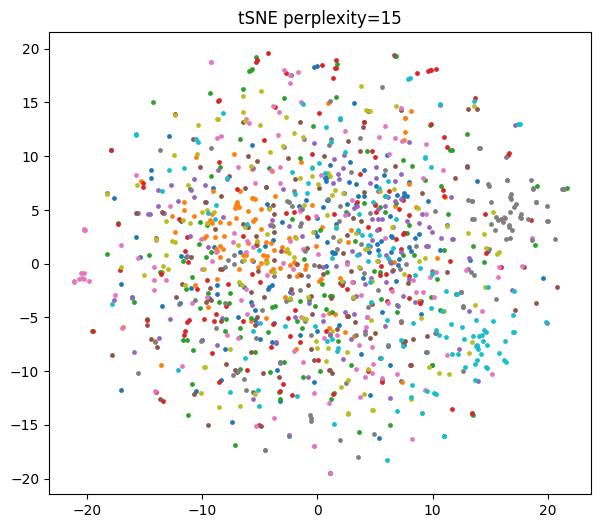

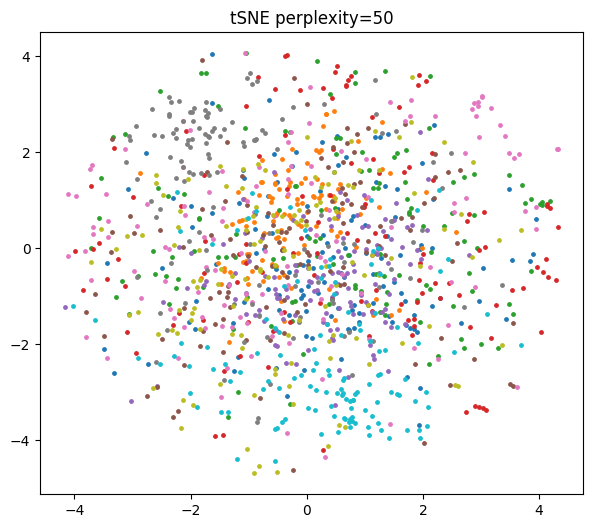

In [25]:
for p in [15, 50]:
    Z = TSNE(n_components=2, perplexity=p, init="pca", random_state=0).fit_transform(mu_val)
    plt.figure(figsize=(7,6))
    for c in range(10):
        m = y_val == c
        plt.scatter(Z[m,0], Z[m,1], s=6, label=names[c])
    plt.title(f"tSNE perplexity={p}")
    plt.savefig(f"/content/repo/results/figures/latent_tSNE_p{p}.png", dpi=150, bbox_inches="tight")
    plt.show()

Top dims: [ 80  14  54  28 112  12  33  71]
base indices: [244, 626, 1135]


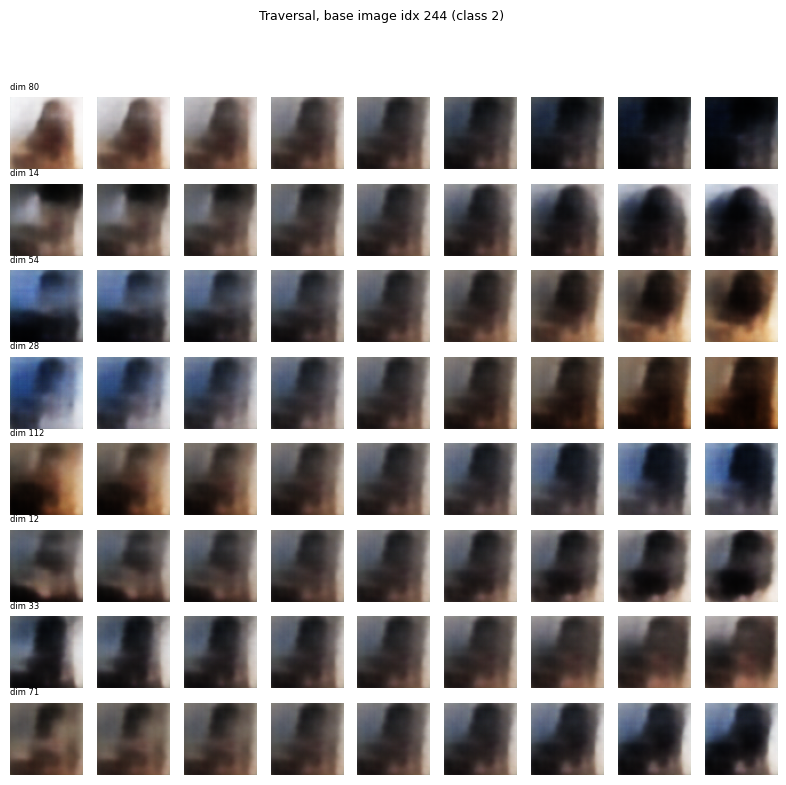

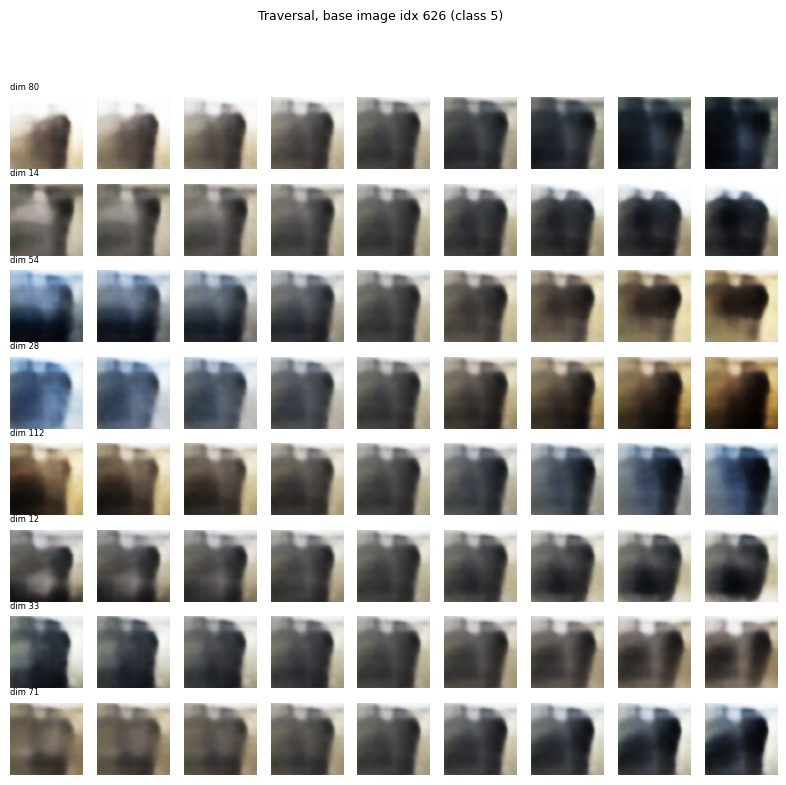

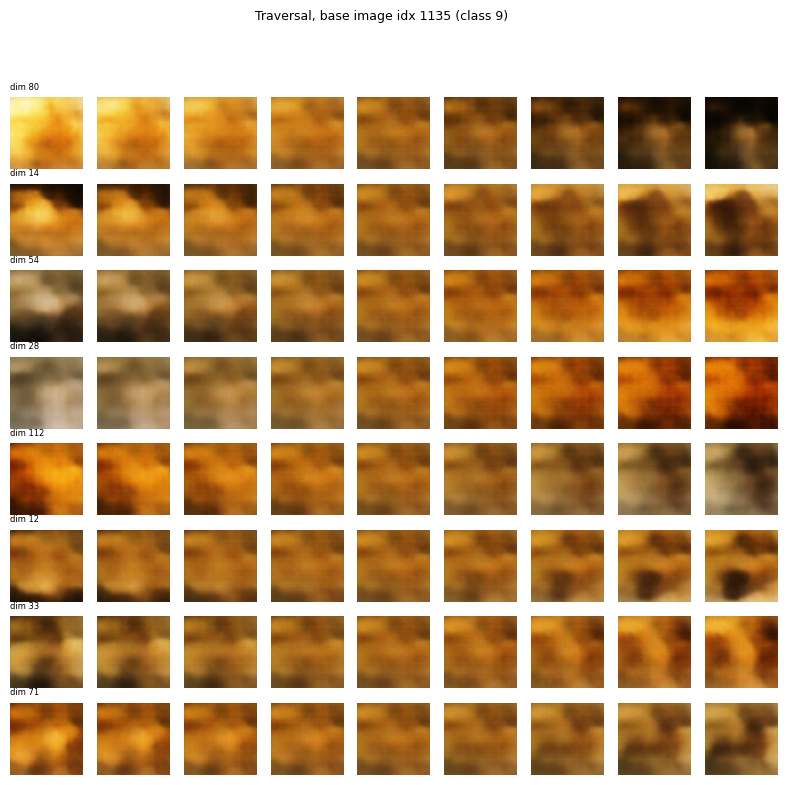

In [27]:
import torch, numpy as np, matplotlib.pyplot as plt

var = mu_val.var(axis=0)
top = np.argsort(-var)[:8]
sigma = np.sqrt(var)
print("Top dims:", top)

base_ids = [int(np.where(y_val == c)[0][0]) for c in [2, 5, 9]]
print("base indices:", base_ids)

steps = 9
alphas = torch.linspace(-3, 3, steps)

def traverse(base_mu, dim):
    # base_mu: [128]
    zs = base_mu.unsqueeze(0).repeat(steps, 1)
    zs[:, dim] = base_mu[dim] + alphas * float(sigma[dim])
    with torch.no_grad():
        return vae.decoder(zs).clamp(0, 1)

for bi in base_ids:
    base_mu = torch.from_numpy(mu_val[bi]).float()      # [128] من غير batch
    fig, axes = plt.subplots(len(top), steps, figsize=(steps*1.1, len(top)*1.1))
    for r, d in enumerate(top):
        imgs = traverse(base_mu, int(d))
        for c in range(steps):
            axes[r, c].imshow(imgs[c].permute(1, 2, 0).numpy())
            axes[r, c].axis("off")
        axes[r, 0].set_title(f"dim {d}", fontsize=6, loc="left")
    plt.suptitle(f"Traversal, base image idx {bi} (class {y_val[bi]})", fontsize=9)
    plt.savefig(f"/content/repo/results/figures/traversal_base{bi}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [28]:
notes = """

### Traversal findings, dims 112, 12, 33, 71, 28 (base idx 244, 626, 1135)
Based on the visible rows of the saved traversal figures. Tentative.

- dim 112: shifts colour along a blue <-> brown/orange axis (blue/grey at -3 sigma,
  brown/dark orange at +3 sigma) on bases 244, 626 and 1135. Appears colour-related.
- dim 12: shifts colour in the opposite direction (brown/orange -> blue/dark).
  Appears colour-related.
- dim 33: mainly changes darkness (grey -> black) on 244 and 626; adds a dark blob
  on 1135. Appears brightness-related.
- dim 71: changes colour/darkness (blue/black -> brown) on 244 and 626; small change on 1135.
- dim 28 (1135): beige/dark -> saturated orange. Colour/saturation.
- Summary: the most active dimensions mainly encode global colour (blue <-> brown/orange)
  and brightness, with little visible object-shape information. This supports prediction 6.
  Several dimensions change colour and brightness together (entangled).
"""
with open("/content/repo/results/latent_notes.md", "a", encoding="utf-8") as f:
    f.write(notes)
print("Saved")

Saved


PAIRS (احفظيهم، لازم نفس الأزواج في M2): {'close_flat_curly': (244, 374), 'far_chainsaw_squash': (626, 1135), 'mid_dhole_flat': (496, 245)}


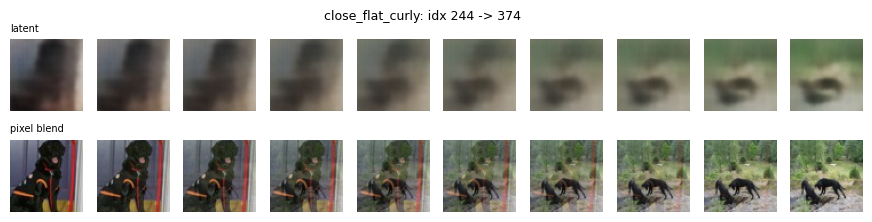

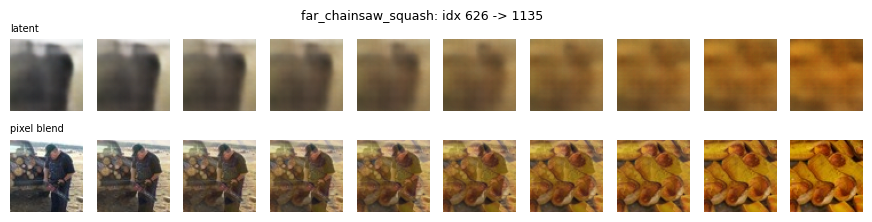

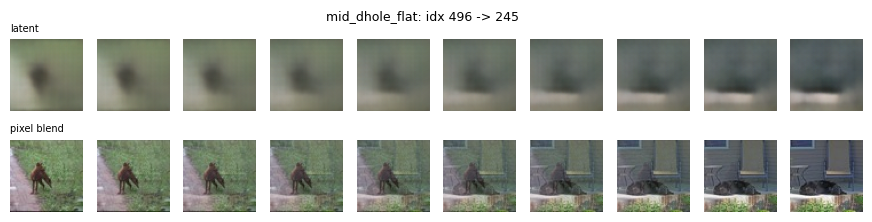

In [29]:
def interp(i, j, steps=10):
    a = torch.linspace(0, 1, steps)[:, None]
    mi = torch.from_numpy(mu_val[i]).float()
    mj = torch.from_numpy(mu_val[j]).float()
    z = (1 - a) * mi + a * mj
    with torch.no_grad():
        return vae.decoder(z).clamp(0, 1)

# أزواج: (قريب) flat↔curly، (بعيد) chain saw↔squash، (متوسط) dhole↔flat-coated
def first(c, k=0): return int(np.where(y_val == c)[0][k])
pairs = {
    "close_flat_curly":   (first(2), first(3)),
    "far_chainsaw_squash": (first(5), first(9)),
    "mid_dhole_flat":     (first(4), first(2, 1)),
}
print("PAIRS (احفظيهم، لازم نفس الأزواج في M2):", pairs)

for name, (i, j) in pairs.items():
    lat = interp(i, j)
    xi = torch.from_numpy(X_val[i]).permute(2, 0, 1).float() / 255
    xj = torch.from_numpy(X_val[j]).permute(2, 0, 1).float() / 255
    a = torch.linspace(0, 1, 10)[:, None, None, None]
    pix = (1 - a) * xi + a * xj
    fig, ax = plt.subplots(2, 10, figsize=(11, 2.4))
    for c in range(10):
        ax[0, c].imshow(lat[c].permute(1, 2, 0).numpy()); ax[0, c].axis("off")
        ax[1, c].imshow(pix[c].permute(1, 2, 0).numpy()); ax[1, c].axis("off")
    ax[0, 0].set_title("latent", fontsize=7, loc="left")
    ax[1, 0].set_title("pixel blend", fontsize=7, loc="left")
    plt.suptitle(f"{name}: idx {i} -> {j}", fontsize=9)
    plt.savefig(f"/content/repo/results/figures/interp_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

import json
json.dump({k: [int(a), int(b)] for k, (a, b) in pairs.items()},
          open("/content/repo/results/interp_pairs.json", "w"), indent=2)

In [30]:
notes = """

### Interpolation findings
Pairs (VAL array indices, saved in results/interp_pairs.json; reuse in M2 Table 2.3):
- close_flat_curly: 244 -> 374
- far_chainsaw_squash: 626 -> 1135
- mid_dhole_flat: 496 -> 245

- In all three pairs the latent interpolation is smooth: colour and brightness change
  gradually from the first image to the second, with no abrupt jumps.
- Intermediate decoded images are blurry colour blobs. Object shape (dog, chain saw,
  squash) is not clearly visible in the middle frames.
- Pixel blending instead shows two superimposed images (ghosting), not a plausible
  intermediate image.
- Even the close pair (flat-coated -> curly-coated) is mostly a colour/background change
  (dark -> green/grey), not a change of dog type. Consistent with the VAE encoding colour
  and lighting more than class identity.
- Caveat: observed visually on 3 pairs only.
"""
with open("/content/repo/results/latent_notes.md", "a", encoding="utf-8") as f:
    f.write(notes)
print("Saved")

Saved


kNN accuracy: 0.21106719367588933


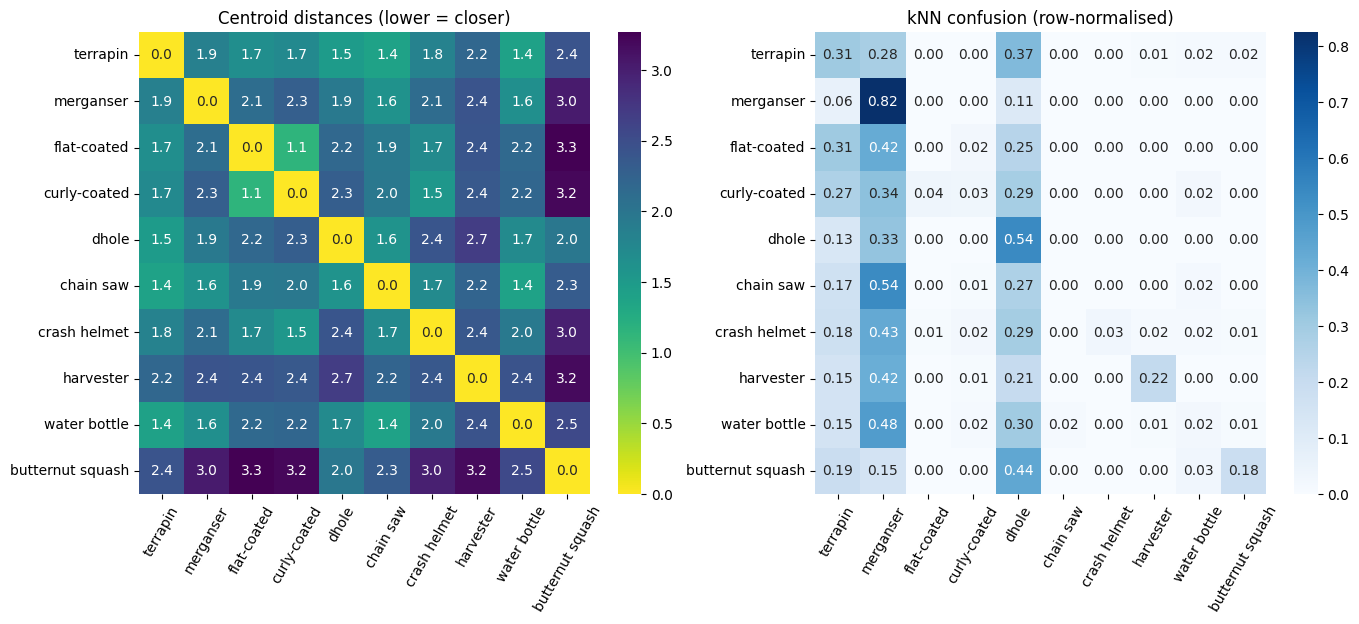

flat-coated <-> curly-coated: 1.14
chain saw <-> water bottle: 1.38
terrapin <-> chain saw: 1.39
terrapin <-> water bottle: 1.40
terrapin <-> dhole: 1.48
true chain saw -> predicted merganser: 0.54
true water bottle -> predicted merganser: 0.48
true butternut squash -> predicted dhole: 0.44
true crash helmet -> predicted merganser: 0.43
true flat-coated -> predicted merganser: 0.42


In [31]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix
import seaborn as sns

names = ["terrapin","merganser","flat-coated","curly-coated","dhole",
         "chain saw","crash helmet","harvester","water bottle","butternut squash"]

# 1) مسافات الـ centroids
cent = np.stack([mu_val[y_val == c].mean(0) for c in range(10)])
dist = np.linalg.norm(cent[:, None] - cent[None], axis=-1)

# 2) kNN confusion (5-fold على VAL)
pred = cross_val_predict(KNeighborsClassifier(10), mu_val, y_val, cv=5)
cm = confusion_matrix(y_val, pred, normalize="true")
print("kNN accuracy:", (pred == y_val).mean())

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(dist, annot=True, fmt=".1f", xticklabels=names, yticklabels=names, ax=ax[0], cmap="viridis_r")
ax[0].set_title("Centroid distances (lower = closer)")
sns.heatmap(cm, annot=True, fmt=".2f", xticklabels=names, yticklabels=names, ax=ax[1], cmap="Blues")
ax[1].set_title("kNN confusion (row-normalised)")
for a in ax: a.tick_params(axis="x", rotation=60)
plt.savefig("/content/repo/results/figures/class_overlap.png", dpi=200, bbox_inches="tight")
plt.show()

# أقرب 5 أزواج
pairs_d = [(dist[i, j], names[i], names[j]) for i in range(10) for j in range(i+1, 10)]
for d, a, b in sorted(pairs_d)[:5]: print(f"{a} <-> {b}: {d:.2f}")

# أكتر 5 أخطاء kNN
off = [(cm[i, j], names[i], names[j]) for i in range(10) for j in range(10) if i != j]
for v, a, b in sorted(off, reverse=True)[:5]: print(f"true {a} -> predicted {b}: {v:.2f}")

In [32]:
notes = """

### Class overlap findings (VAL latent means, z128)
- kNN (k=10, 5-fold on VAL) accuracy = 0.211 (chance about 0.10): class information in the latent means is weak.
- Closest centroid pairs: flat-coated<->curly-coated 1.14; chain saw<->water bottle 1.38;
  terrapin<->chain saw 1.39; terrapin<->water bottle 1.40; terrapin<->dhole 1.48.
- Largest kNN confusions: chain saw->merganser 0.54; water bottle->merganser 0.48;
  butternut squash->dhole 0.44; crash helmet->merganser 0.43; flat-coated->merganser 0.42.
- Merganser is the only class recognised well (recall 0.82) and acts as an attractor for other classes.
  Hypothesis (not verified): it occupies a dense central region of the latent space.
- Predictions check: (1) retrievers overlap: supported (closest pair). (2) dhole near retrievers: NOT supported
  (centroid distances about 2.2-2.3). (3) terrapin/merganser overlap: NOT supported (1.9). (4) chain saw, water
  bottle, squash separated: NOT supported by kNN (squash is far in centroid distance but confused with dhole).
  (5) classes overlap a lot: supported. (6) top dims encode colour/brightness: supported by traversals.
- Caveats: single VAE, VAL only, centroid distance is not the same as separability.
"""
with open("/content/repo/results/latent_notes.md", "a", encoding="utf-8") as f:
    f.write(notes)
print("Saved")

Saved


flat->curly: [246 298 359] | curly->flat: [405 415 430 435]
counts: flat->curly 3 | curly->flat 5


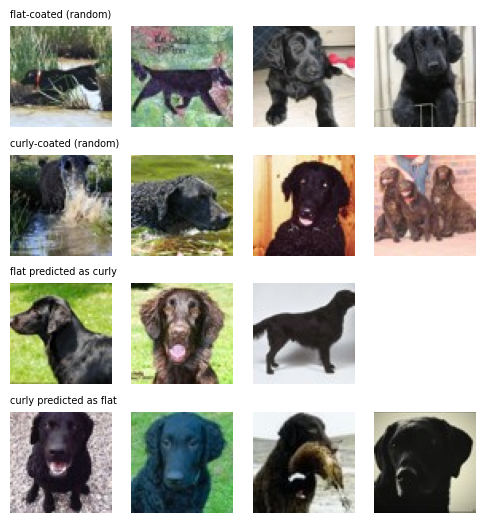

In [33]:
import numpy as np, torch, matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_predict

# توقعات kNN (نفس اللي استخدمناه قبل كده)
pred = cross_val_predict(KNeighborsClassifier(10), mu_val, y_val, cv=5)

# 1) صور عشوائية من الـ class 2 (flat) و 3 (curly) بـ seed ثابت
rng = np.random.RandomState(0)
flat_ids  = rng.choice(np.where(y_val == 2)[0], 4, replace=False)
curly_ids = rng.choice(np.where(y_val == 3)[0], 4, replace=False)

# 2) أمثلة متلخبطة: flat اتصنّف curly، و curly اتصنّف flat
flat_as_curly = np.where((y_val == 2) & (pred == 3))[0][:4]
curly_as_flat = np.where((y_val == 3) & (pred == 2))[0][:4]
print("flat->curly:", flat_as_curly, "| curly->flat:", curly_as_flat)
print("counts: flat->curly", ((y_val==2)&(pred==3)).sum(),
      "| curly->flat", ((y_val==3)&(pred==2)).sum())

rows = [("flat-coated (random)", flat_ids),
        ("curly-coated (random)", curly_ids),
        ("flat predicted as curly", flat_as_curly),
        ("curly predicted as flat", curly_as_flat)]

fig, axes = plt.subplots(len(rows), 4, figsize=(6, len(rows) * 1.6))
for r, (title, ids) in enumerate(rows):
    for c in range(4):
        axes[r, c].axis("off")
        if c < len(ids):
            axes[r, c].imshow(X_val[ids[c]])
    axes[r, 0].set_title(title, fontsize=7, loc="left")
plt.savefig("/content/repo/results/figures/overlap_flat_curly_examples.png",
            dpi=200, bbox_inches="tight")
plt.show()

In [34]:
notes = """

### Examples of overlapping classes (flat-coated vs curly-coated retriever)
Figure: results/figures/overlap_flat_curly_examples.png (4 random images per class, seed 0;
misclassified indices: flat->curly [246 298 359], curly->flat [405 415 430 435]).

- Direct flat<->curly confusion by kNN is rare: 3 flat images predicted curly, 5 curly images predicted flat
  (about 130 images per class). The two classes are the closest centroid pair (1.14), yet kNN mostly
  confuses them with merganser, not with each other.
- Visually, images of both classes are dark dogs with very varied backgrounds (grass, water, indoor,
  close-up puppies). At 64x64 the difference between smooth and curly coat is hard to see, while background and
  lighting vary a lot within each class. This is a plausible explanation for the overlap (visual inspection of
  a small sample, not verified).
"""
with open("/content/repo/results/latent_notes.md", "a", encoding="utf-8") as f:
    f.write(notes)
print("Saved")

Saved


In [35]:
final = """# Latent Analysis (Milestone 1, Member C)

Model: final VAE (z128, beta = 1.0, 10-epoch KL warm-up). All analysis uses VAL latent means (n = 1265), fixed seed 0. TEST was not used.

## 1. Active units
All 128 / 128 dimensions pass the variance > 0.01 threshold (min var 0.0129, max 1.647), matching Member B's Table 1.2. Because the threshold does not discriminate, dimensions were ranked by var(mu) for the traversals (top 8: 80, 14, 54, 28, 112, 12, 33, 71).

## 2. t-SNE / UMAP
Figures: latent_tSNE.png, latent_UMAP.png (t-SNE perplexity 30, UMAP n_neighbors 15). Classes are heavily mixed with no clear clusters. Only butternut squash forms a visibly more compact region in UMAP. Global distances in these projections are distorted and were not interpreted.

## 3. Latent traversals
Base images 244 (flat-coated), 626 (chain saw), 1135 (butternut squash); each dimension varied from -3 to +3 sigma.
- dim 80 darkens the image in all three bases (appears brightness-related).
- dims 112, 12 and 71 mainly shift colour along a blue <-> brown/orange axis; dim 33 mainly changes darkness.
- dim 14 acts differently on each base image (entangled).
Little object-shape information is visible; most dimensions change colour and brightness together. Decoded images are blurry (pixel-wise loss at 64x64). Observations are visual, on three base images.

## 4. Interpolation
Pairs (VAL indices, results/interp_pairs.json, to be reused in M2 Table 2.3): close 244 -> 374 (flat-coated -> curly-coated), far 626 -> 1135 (chain saw -> squash), mid 496 -> 245 (dhole -> flat-coated).
Latent interpolation is smooth in colour and brightness, but intermediate frames are blurry colour blobs without a clear object. Pixel blending gives superimposed images (ghosting). Even the close pair changes mostly colour/background.

## 5. Class overlap
- kNN (k = 10, 5-fold on VAL) accuracy is 0.211 (chance about 0.10), so class information is weak.
- Closest centroid pairs: flat-coated/curly-coated 1.14, chain saw/water bottle 1.38, terrapin/chain saw 1.39, terrapin/water bottle 1.40, terrapin/dhole 1.48. Butternut squash is the most distant class (2.0 to 3.3).
- Largest confusions: chain saw -> merganser 0.54, water bottle -> merganser 0.48, butternut squash -> dhole 0.44. Merganser (recall 0.82) acts as an attractor; we hypothesise it occupies a dense central region (not verified).
- Flat-coated and curly-coated are the closest pair, but are rarely confused directly by kNN (3 and 5 images). Visually, both are dark dogs with very varied backgrounds, and the smooth/curly coat difference is hard to see at 64x64 (small visual sample).
- Predictions: retriever overlap supported; dhole near retrievers, terrapin/merganser overlap, and separation of chain saw/water bottle/squash not supported.

## 6. Why
The VAE is trained only to reconstruct, so its latent space is organised mainly by colour, brightness and background rather than class. Traversals, interpolations and kNN results all agree with this.

Limitations: one VAE, VAL only, visual inspection on few examples, centroid distance is not separability.
"""
with open("/content/repo/results/latent_analysis_section.md", "w", encoding="utf-8") as f:
    f.write(final)
print("Saved")

Saved


In [37]:
%cd /content/repo
!git checkout -b m1-latent-analysis
!git config user.name "Nourhan Alaa"
!git config user.email "nourhanalaa648@gmail.com"
!git add results/figures results/predictions.md results/latent_notes.md results/latent_analysis_section.md results/interp_pairs.json
!git commit -m "M1 Member C: latent analysis"

/content/repo
fatal: a branch named 'm1-latent-analysis' already exists
On branch m1-latent-analysis
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	results/Ppredictions
	results/mu_val.npy
	results/y_val.npy

nothing added to commit but untracked files present (use "git add" to track)


In [38]:
!git commit --amend --reset-author --no-edit
!git log -1 --format="%an <%ae>"

[m1-latent-analysis 02d0b54] M1 Member C: latent analysis
 16 files changed, 125 insertions(+)
 create mode 100644 results/figures/class_overlap.png
 create mode 100644 results/figures/interp_close_flat_curly.png
 create mode 100644 results/figures/interp_far_chainsaw_squash.png
 create mode 100644 results/figures/interp_mid_dhole_flat.png
 create mode 100644 results/figures/latent_UMAP.png
 create mode 100644 results/figures/latent_tSNE.png
 create mode 100644 results/figures/latent_tSNE_p15.png
 create mode 100644 results/figures/latent_tSNE_p50.png
 create mode 100644 results/figures/overlap_flat_curly_examples.png
 create mode 100644 results/figures/traversal_base1135.png
 create mode 100644 results/figures/traversal_base244.png
 create mode 100644 results/figures/traversal_base626.png
 create mode 100644 results/interp_pairs.json
 create mode 100644 results/latent_analysis_section.md
 create mode 100644 results/latent_notes.md
Nourhan Alaa <nourhanalaa648@gmail.com>


In [43]:
from getpass import getpass
token = getpass("GitHub token: ")
!git push https://{token}@github.com/EngineerAmor/Learning-ImageNet-Representations-with-Variational-Autoencoders-and-GANs.git m1-latent-analysis

GitHub token: ··········
fatal: could not read Password for 'https://123@github.com': No such device or address
